# CellTypist annotation of the cleaned Parse dataset

This notebook works **only** from the cleaned, clustered dataset
(`adata_clustered_res_0_6.h5ad`) and never overwrites it. Results are saved as CSVs/figures
in a separate `celltypist` folder.

**What we do, in order**

| Step | Question | CellTypist model |
|---|---|---|
| 0 | Prepare the data in the format CellTypist expects | – |
| 1 | What is the *primary* cell type of each Leiden cluster? (e.g. "cluster 2 is 96% B cells") | `Immune_All_High` (32 broad types) |
| 2 | Within the **B cell** clusters: GCBC vs MBC vs proliferative GCBC | `Immune_All_Low` (98 fine types) |
| 3 | Within the **T cell** clusters: Tcm/naïve helper, Tem/effector helper, Tem/Trm cytotoxic, cycling, Tem/Temra cytotoxic, Treg | `Immune_All_Low` |
| 4 | Save everything | – |
| Appendix | Re-implementation of the collaborator's R function (90% probability threshold), for comparison | `Immune_All_Low` |

**A 30-second primer on CellTypist**

* CellTypist is a pre-trained **logistic regression** classifier. Each model was trained on a large
  reference atlas (here: immune cells from 20 tissues, Domínguez Conde *et al.*, Science 2022).
* For every cell it outputs a **probability for every cell type** in the model. These are
  "one-vs-rest" probabilities: each one independently answers *"is this cell type X, yes or no?"*,
  so they do **not** sum to 1 across cell types.
* The *predicted label* is simply the cell type with the highest probability.
* Because classification is done one cell at a time, running it on a subset of cells gives
  exactly the same answer for those cells as running it on the whole dataset.

## Setup
### Imports

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy import sparse

import celltypist                 # the classifier itself
from celltypist import models     # helpers to download / load pre-trained models

warnings.filterwarnings("ignore")
sc.settings.set_figure_params(dpi=100, facecolor="white")

c:\Users\taylorhearn\AppData\Local\miniforge3\envs\sequencing\lib\site-packages\louvain\__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### Paths, colours and condition names
The colour map and condition renaming are copied from `parse_biosciences_seq.ipynb`, so
clusters and conditions look the same in both notebooks.

In [2]:
# Input: the cleaned dataset. We only ever READ this file.
clean_matrix = r"C:\Users\taylorhearn\Desktop\scRNA\adata_clustered_res_0_6.h5ad"

# Output: a new folder for everything this notebook produces.
outdir = Path(r"C:\Users\taylorhearn\Desktop\scRNA\celltypist")
outdir.mkdir(parents=True, exist_ok=True)
sc.settings.figdir = outdir   # scanpy's save=... arguments write here

# --- Same colours / names as the main notebook ---
cluster_colourmap = {
    "0": "#F5C423", "1": "#5B5DE6", "2": "#E16ED1", "3": "#2E9BD3", "4": "#8B3FD1",
    "5": "#F06B2D", "6": "#C32A71", "7": "#238F42", "8": "#A7C83A",
}
condition_mapping = {
    "Bead": "Vasculature",
    "FL_Chip_minus": "iFL_V+",
    "FL_Chip_plus": "tFL_V+",
    "FL_ULA_minus": "iFL_V-",
    "FL_ULA_plus": "tFL_V-",
    "rLN_Chip_minus": "irLN_V+",
    "rLN_ULA_minus": "irLN_V-",
}
condition_order = ["Vasculature", "irLN_V-", "irLN_V+", "iFL_V-", "iFL_V+", "tFL_V-", "tFL_V+"]

# A colour-blind-safe categorical palette for cell-type labels. Colours are handed out
# in this fixed order, and "uncertain" categories (Mixed / Low confidence / Other) are grey.
category_palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                    "#e87ba4", "#008300", "#6250d6", "#e34948"]
grey = "#b5b5b5"

### Small plotting helpers
Two helpers we use several times below. You don't need to understand them to follow the
analysis. They just draw stacked bar charts and match colours to labels.

In [3]:
def make_colour_dict(labels, grey_labels=("Mixed", "Low confidence", "Other")):
    # Give each label a colour from category_palette (in order); uncertain labels get grey.
    colours, i = {}, 0
    for label in labels:
        if any(label.startswith(g) for g in grey_labels):
            colours[label] = grey
        else:
            colours[label] = category_palette[i % len(category_palette)]
            i += 1
    return colours


def plot_stacked_fractions(table, colours, title, xlabel, filename=None, figsize=(8, 4)):
    # table: rows = bars (e.g. clusters), columns = categories, values = fractions (rows sum to 1).
    ax = table.plot(kind="bar", stacked=True, figsize=figsize, width=0.85,
                    color=[colours[c] for c in table.columns], edgecolor="white", linewidth=1)
    ax.set_ylabel("Fraction of cells")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)   # scanpy's style turns gridlines on; they clutter stacked bars
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=9)
    plt.xticks(rotation=0)
    plt.tight_layout()
    if filename is not None:
        plt.savefig(outdir / filename, bbox_inches="tight", dpi=200)
    plt.show()

## Step 0: Load the data and prepare the CellTypist input

### 0a. Load the cleaned dataset

In [4]:
adata = sc.read_h5ad(clean_matrix)

# Rename conditions to the short names used elsewhere, and fix the order of categories.
adata.obs["condition"] = pd.Categorical(
    adata.obs["condition"].astype(str).replace(condition_mapping),
    categories=condition_order,
)
adata.obs["clusters"] = adata.obs["clusters"].astype("category")
adata.uns["clusters_colors"] = [cluster_colourmap[c] for c in adata.obs["clusters"].cat.categories]

print(adata)
print("\nCells per cluster:")
print(adata.obs["clusters"].value_counts().sort_index())

AnnData object with n_obs × n_vars = 58644 × 55689
    obs: 'bc_wells', 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'n_genes', 'n_counts', 'leiden_0.2', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'clusters'
    var: 'gene_id', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'clusters_colors', 'condition_colors', 'dendrogram_clusters', '

### 0b. Build the input CellTypist expects
-> scale each cell so its counts add up to 10,000
-> gene value is transformed into "of every 10,000 molecules in this cell, how many came from this gene"
-> then log transform to compress the range so a few v highly expressed genes don't dominate

CellTypist models were trained on data that was:
1. **normalised to 10,000 counts per cell** (`sc.pp.normalize_total(target_sum=1e4)`), then
2. **log-transformed** with `log1p`.

Our input must be prepared the same way, or the probabilities are meaningless. `adata.X` in
the cleaned file is log-transformed but normalised to a different total, so we rebuild a clean
version from the raw integer counts in `adata.layers["counts"]`.

We put it in a **separate, lightweight AnnData** (`ct_input`) so `adata` stays exactly as
it was loaded.

In [5]:
ct_input = sc.AnnData(
    X=adata.layers["counts"].copy(),                         # raw integer UMI counts
    obs=adata.obs[["clusters", "sample", "condition"]].copy(),  # cell metadata we want to keep
    var=pd.DataFrame(index=adata.var_names),                 # gene names
)
ct_input.obsm["X_pca_harmony"] = adata.obsm["X_pca_harmony"]   # used later to draw sub-UMAPs

sc.pp.normalize_total(ct_input, target_sum=1e4)   # every cell now sums to 10,000
sc.pp.log1p(ct_input)                             # natural log(x + 1)

# Sanity check: undoing the log (expm1) should give back ~10,000 for every cell.
first_cells = ct_input.X[:5]
first_cells = first_cells.toarray() if sparse.issparse(first_cells) else first_cells
print("Counts per cell after undoing the log:", np.expm1(first_cells).sum(axis=1).round())

Counts per cell after undoing the log: [10000. 10000. 10000. 10000. 10000.]


### 0c. Download and load the two models

* `Immune_All_High`: **32 broad** types (B cells, T cells, Plasma cells, Endothelial cells, Fibroblasts…). Broad model to assign each cluster a lineage
  The right tool for "what lineage is this?"
* `Immune_All_Low`: **98 fine** subtypes (Germinal center B cells, Memory B cells, Regulatory T cells…). The model Victor used for "What type of B/T cell is this"t
Models are downloaded once to `~/.celltypist/data/models` and reused afterwards.

In [6]:
for model_name in ["Immune_All_High.pkl", "Immune_All_Low.pkl"]:
    if not Path(models.get_model_path(model_name)).exists():
        models.download_models(model=model_name)

high_model = models.Model.load("Immune_All_High.pkl")
low_model = models.Model.load("Immune_All_Low.pkl")
print(high_model, "\n")
print(low_model)

# How many of the model's genes exist in our data? (missing genes are treated as 0)
n_shared = len(set(low_model.features) & set(ct_input.var_names))
print(f"\nGenes shared with the Low model: {n_shared} / {len(low_model.features)}")

CellTypist model with 32 cell types and 6639 features
    date: 2022-07-16 08:53:00.959521
    details: immune populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: B cells, B-cell lineage, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX 

CellTypist model with 98 cell types and 6639 features
    date: 2022-07-16 00:20:42.927778
    details: immune sub-populations combined from 20 tissues of 18 studies
    source: https://doi.org/10.1126/science.abl5197
    version: v2
    cell types: Age-associated B cells, Alveolar macrophages, ..., pDC precursor
    features: A1BG, A2M, ..., ZYX

Genes shared with the Low model: 5889 / 6639


## Step 1: Primary cell type of each cluster

### 1a. Annotate every cell with the High (broad) model

`celltypist.annotate` returns an object with two tables we care about:
* `.predicted_labels`: one row per cell, column `predicted_labels` = the best-scoring type
* `.probability_matrix`: one row per cell, one column per cell type

`majority_voting=False` means **we don't let CellTypist re-cluster the data and smooth labels
within its own clusters**. We want the raw per-cell call so that *we* can summarise it over
*our* Leiden clusters.

In [7]:
high_pred = celltypist.annotate(ct_input, model=high_model, majority_voting=False)

# .loc[adata.obs_names] guarantees the rows line up with adata, cell by cell.
adata.obs["ct_high_label"] = high_pred.predicted_labels.loc[adata.obs_names, "predicted_labels"].values
adata.obs["ct_high_prob"] = high_pred.probability_matrix.loc[adata.obs_names].max(axis=1).values

adata.obs[["clusters", "ct_high_label", "ct_high_prob"]].head()

🔬 Input data has 58644 cells and 55689 genes
🔗 Matching reference genes in the model
🧬 5889 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


,clusters,ct_high_label,ct_high_prob
bc_wells,,,
32_02_32__s1,1,Fibroblasts,1.000000
32_03_52__s1,6,Endothelial cells,1.000000
32_04_61__s1,1,Fibroblasts,0.984096
32_07_83__s1,0,Endothelial cells,0.999993
32_08_29__s1,1,Fibroblasts,0.999986


### 1b. Group the fine-ish High labels into lineages

A few High labels belong together for our question. For example, "Plasma cells" are part of
the B lineage, as in your collaborator's `blin` list. "Cycling cells" is kept as its own group
because the High model cannot tell *which* lineage is dividing. Anything not listed becomes
"Other".

In [8]:
lineage_groups = {
    "B lineage":   ["B cells", "B-cell lineage", "Plasma cells"],
    "T cells":     ["T cells", "Double-negative thymocytes", "Double-positive thymocytes", "ETP"],
    "NK/ILC":      ["ILC", "ILC precursor"],
    "Myeloid":     ["Macrophages", "Monocytes", "Mono-mac", "MNP", "DC", "DC precursor", "pDC",
                    "pDC precursor", "Mast cells", "Granulocytes", "Monocyte precursor",
                    "Myelocytes", "Promyelocytes"],
    "Endothelial": ["Endothelial cells"],
    "Fibroblasts": ["Fibroblasts"],
    "Epithelial":  ["Epithelial cells"],
    "Cycling (lineage unclear)": ["Cycling cells"],
}

# Flip the dictionary round: {"B cells": "B lineage", "Plasma cells": "B lineage", ...}
label_to_lineage = {label: lineage for lineage, labels in lineage_groups.items() for label in labels}

adata.obs["ct_lineage"] = adata.obs["ct_high_label"].map(label_to_lineage).fillna("Other")
adata.obs["ct_lineage"].value_counts()

ct_lineage
Endothelial                  26063
B lineage                    15422
Fibroblasts                   9541
T cells                       4435
Myeloid                       1816
NK/ILC                        1090
Cycling (lineage unclear)      148
Epithelial                      73
Other                           56
Name: count, dtype: int64

### 1c. What fraction of each cluster is each lineage?

`pd.crosstab(..., normalize="index")` counts cells for every (cluster, lineage) pair and
divides each row by its total, giving the fraction of each cluster belonging to each lineage.

In [9]:
lineage_by_cluster = pd.crosstab(adata.obs["clusters"], adata.obs["ct_lineage"], normalize="index")

# Drop lineages that never reach 1% in any cluster, to keep the table readable.
lineage_by_cluster = lineage_by_cluster.loc[:, lineage_by_cluster.max() >= 0.01]

(lineage_by_cluster * 100).round(1)   # shown as percentages

ct_lineage,B lineage,Cycling (lineage unclear),Endothelial,Fibroblasts,Myeloid,NK/ILC,T cells
clusters,,,,,,,
0,0.0,0.0,99.9,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,88.0,7.5,3.3,0.1
2,97.5,0.1,0.1,0.0,0.4,0.5,1.2
3,89.1,3.1,0.4,0.2,3.2,0.8,2.2
4,0.6,0.0,0.1,0.0,0.1,1.3,97.9
5,6.9,0.1,28.6,8.7,23.6,16.7,13.8
6,0.0,0.0,99.9,0.0,0.1,0.0,0.0
7,96.1,0.1,0.1,0.0,0.1,0.7,2.8
8,0.0,0.0,96.3,3.4,0.0,0.3,0.0


### 1d. Designate each cluster

**Rule:** if one lineage makes up at least `designation_threshold` (80%) of a cluster's cells,
the cluster is named after that lineage. Otherwise it is "Mixed", and we list the two biggest
contributors so you can see what it's mixed between.

80% is a judgement call. Change it and re-run to see which clusters flip.

In [10]:
designation_threshold = 0.80

def designate_cluster(fractions, threshold):
    # fractions: one row of lineage_by_cluster, e.g. {"B lineage": 0.96, "T cells": 0.01, ...}
    if fractions.max() >= threshold:
        return fractions.idxmax()
    top_two = fractions.sort_values(ascending=False).head(2)
    return "Mixed (" + " / ".join(f"{name} {frac:.0%}" for name, frac in top_two.items()) + ")"

cluster_summary = pd.DataFrame({
    "n_cells": adata.obs["clusters"].value_counts().sort_index(),
    "top_lineage": lineage_by_cluster.idxmax(axis=1),
    "top_lineage_pct": (lineage_by_cluster.max(axis=1) * 100).round(1),
    "designation": lineage_by_cluster.apply(designate_cluster, axis=1, threshold=designation_threshold),
})
cluster_summary.index.name = "cluster"

# Store the designation on every cell too (handy for plotting / later subsetting).
adata.obs["cluster_designation"] = adata.obs["clusters"].map(cluster_summary["designation"]).astype("category")

cluster_summary.to_csv(outdir / "cluster_designation.csv")
cluster_summary

,n_cells,top_lineage,top_lineage_pct,designation
cluster,,,,
0,21192,Endothelial,99.9,Endothelial
1,10454,Fibroblasts,88.0,Fibroblasts
2,10153,B lineage,97.5,B lineage
3,4369,B lineage,89.1,B lineage
4,3754,T cells,97.9,T cells
5,3535,Endothelial,28.6,Mixed (Endothelial 29% / Myeloid 24%)
6,3179,Endothelial,99.9,Endothelial
7,1417,B lineage,96.1,B lineage
8,591,Endothelial,96.3,Endothelial


### 1e. Visualise it

* **Bar chart:** the lineage make-up of each cluster (the table above, as a picture).
* **UMAPs:** left = your Leiden clusters, middle = per-cell lineage call, right = cluster designation.

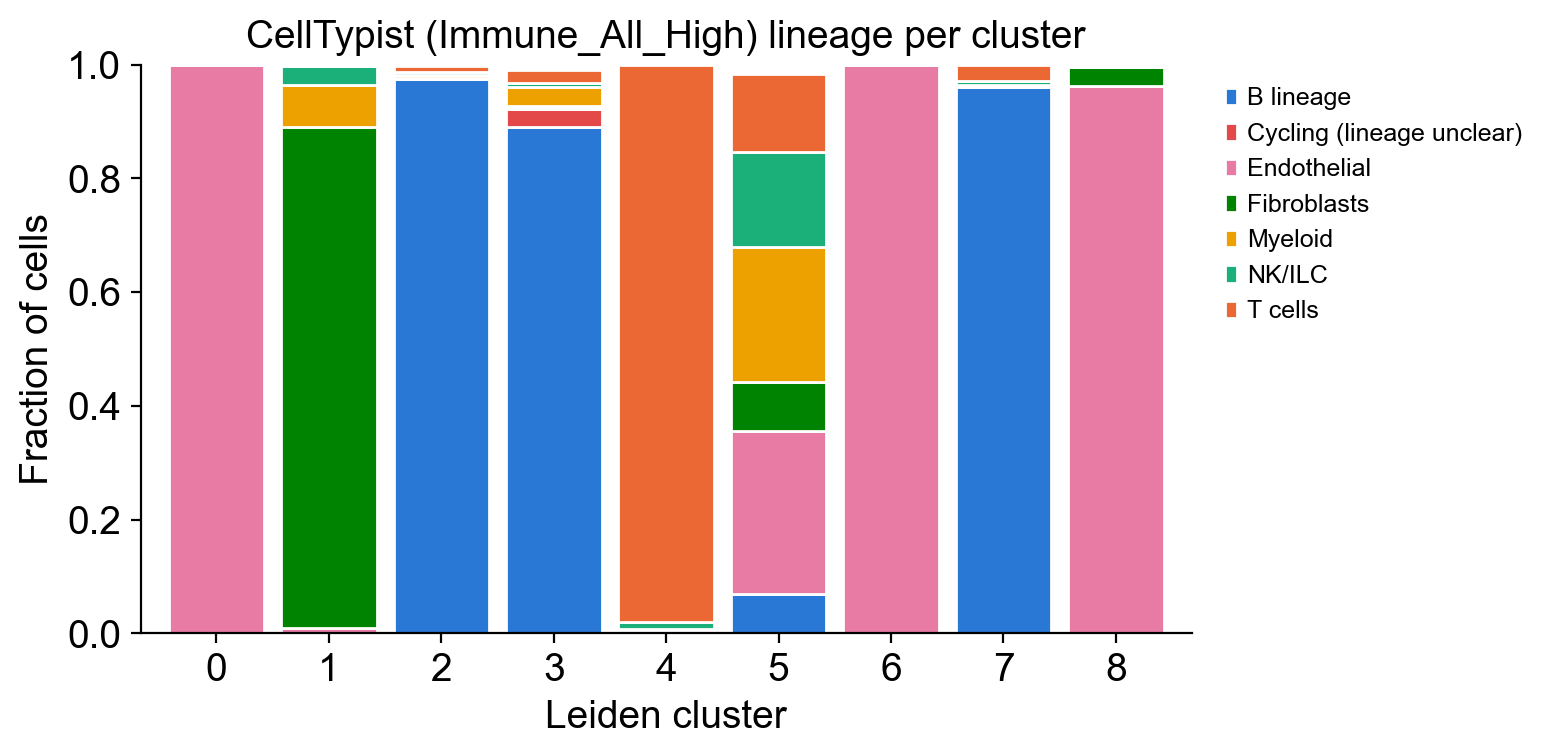

In [11]:
# ONE colour per lineage, fixed by the order of lineage_groups, and used in every plot below,
# so "B lineage" is the same colour in the bar chart and both UMAPs. "Other" is grey.
lineage_colours = make_colour_dict(list(lineage_groups) + ["Other"])

plot_stacked_fractions(lineage_by_cluster, lineage_colours,
                       title="CellTypist (Immune_All_High) lineage per cluster",
                       xlabel="Leiden cluster", filename="lineage_per_cluster.png")

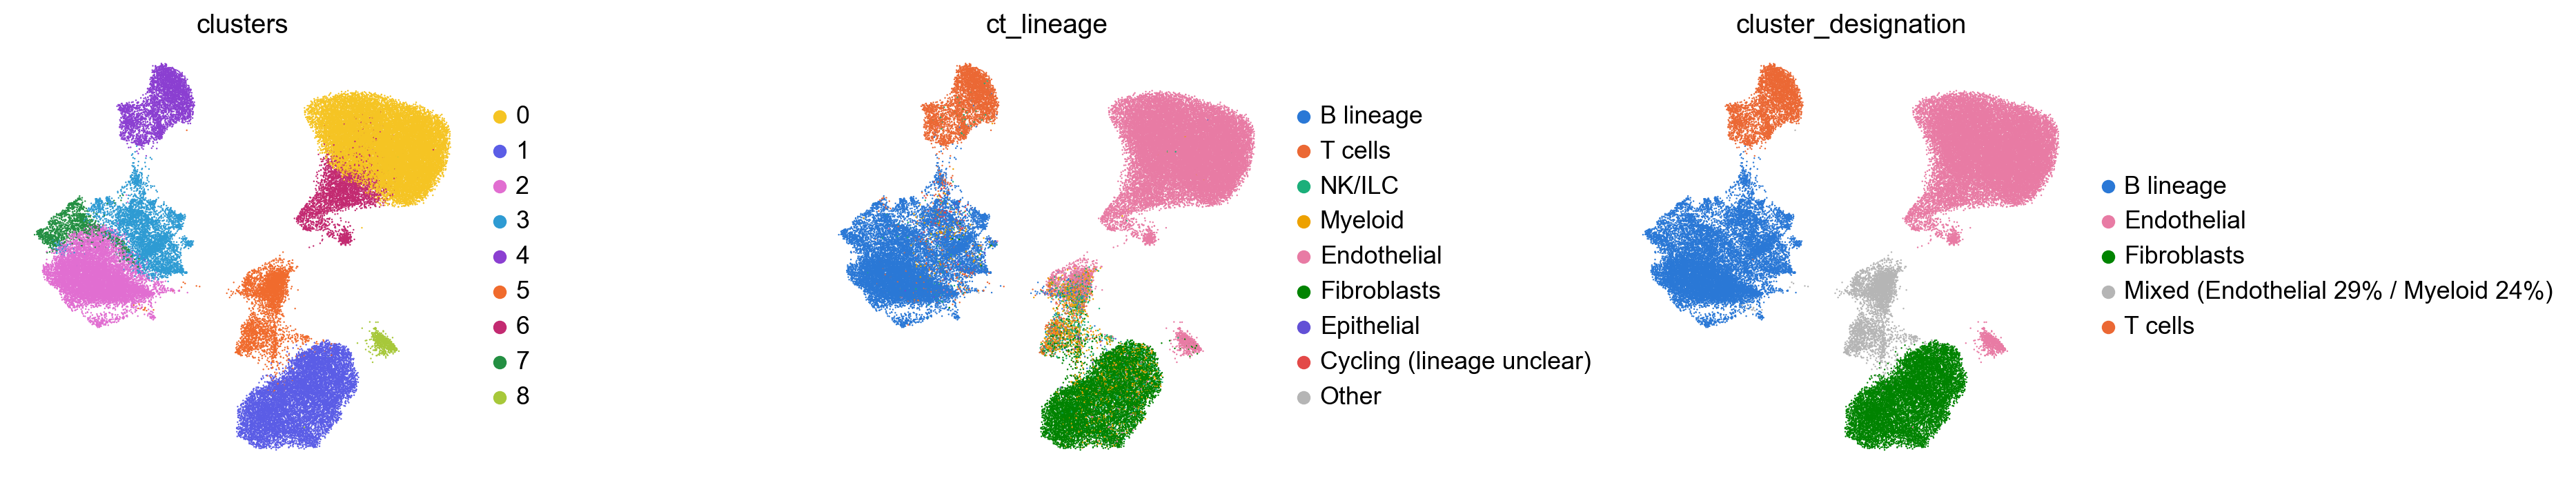

In [12]:
# scanpy reads category colours from adata.uns["<column>_colors"], in category order.
lineages_present = [l for l in lineage_colours if l in set(adata.obs["ct_lineage"])]
adata.obs["ct_lineage"] = pd.Categorical(adata.obs["ct_lineage"], categories=lineages_present)
adata.uns["ct_lineage_colors"] = [lineage_colours[l] for l in lineages_present]

# A designated cluster takes its lineage's colour; "Mixed (...)" clusters are grey.
adata.uns["cluster_designation_colors"] = [lineage_colours.get(d, grey)
                                           for d in adata.obs["cluster_designation"].cat.categories]

sc.pl.umap(adata, color=["clusters", "ct_lineage", "cluster_designation"],
           legend_loc="right margin", wspace=0.6, frameon=False, size=3,
           save="_lineage_overview.png")

**How confident was the model?** `ct_high_prob` is the probability of the winning label. A
cluster where most cells are close to 1 is a clean call; a broad spread down towards 0 means
the model struggled (e.g. mixed, low-quality or doublet cells, or a cell type the model
doesn't know).

Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


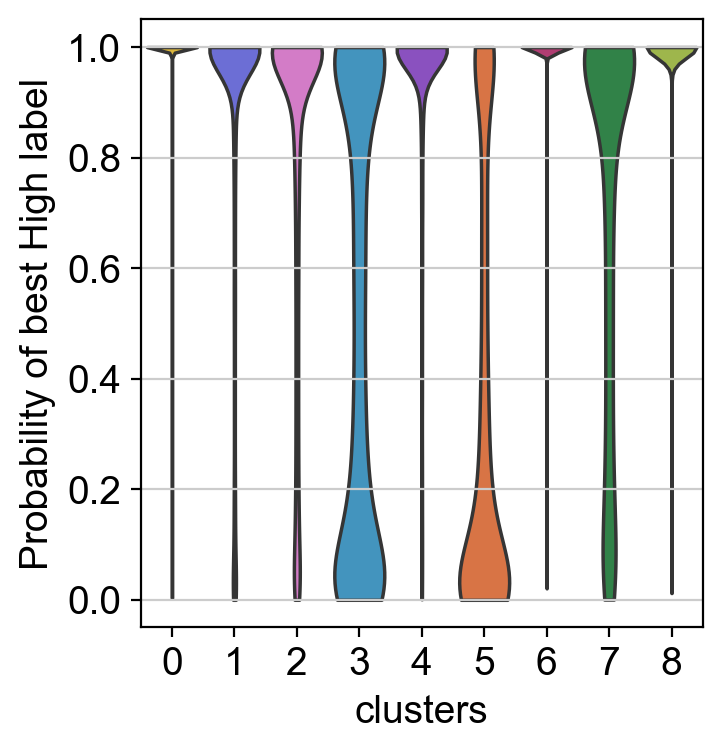

In [13]:
sc.pl.violin(adata, keys="ct_high_prob", groupby="clusters", stripplot=False,
             ylabel="Probability of best High label", save="_high_model_confidence.png")

## Step 2: B cell subtypes

### 2a. Which cells go into the B cell subtype analysis?

Two filters, both explained:
1. **Cluster filter:** clusters whose designation is "B lineage" (from Step 1).
2. **Cell filter:** inside those clusters, keep only cells the High model called a B cell
   (`"B cells"`, `"B-cell lineage"`) or `"Cycling cells"`. Cycling cells are kept because
   dividing B cells are exactly where *proliferative GCBC* will come from. We **drop**:
   * stray T/NK/myeloid cells sitting in a B cluster (they'd otherwise be forced into a B subtype)
   * plasma cells (they are B lineage, but not GCBC/MBC, so they'd be mis-forced too)

In [14]:
b_clusters = cluster_summary.index[cluster_summary["designation"] == "B lineage"].tolist()
print("B lineage clusters:", b_clusters)

b_allowed_high_labels = ["B cells", "B-cell lineage", "Cycling cells"]

in_b_cluster = adata.obs["clusters"].isin(b_clusters)
is_b_cell = adata.obs["ct_high_label"].isin(b_allowed_high_labels)
b_mask = in_b_cluster & is_b_cell

print(f"Cells in B clusters:         {in_b_cluster.sum()}")
print(f"  kept for subtyping:        {b_mask.sum()}")
print(f"  excluded (by High label):")
print(adata.obs.loc[in_b_cluster & ~is_b_cell, "ct_high_label"].astype(str).value_counts().to_string())

b_cells = ct_input[b_mask.values].copy()

B lineage clusters: ['2', '3', '7']
Cells in B clusters:         15939
  kept for subtyping:        13538
  excluded (by High label):
ct_high_label
Plasma cells                  1760
T cells                        245
DC                             123
ILC                             97
Macrophages                     47
Epithelial cells                47
Endothelial cells               28
Fibroblasts                     14
Double-positive thymocytes       8
HSC/MPP                          8
DC precursor                     8
Erythroid                        4
Double-negative thymocytes       4
Monocytes                        4
Myelocytes                       3
ILC precursor                    1


### 2b. Run the Low (fine) model on the B cells

In [15]:
b_pred = celltypist.annotate(b_cells, model=low_model, majority_voting=False)
b_prob = b_pred.probability_matrix          # cells x 98 fine cell types

# The unconstrained answer: the best of ALL 98 fine labels.
b_cells.obs["low_best_label"] = b_pred.predicted_labels["predicted_labels"].values
b_cells.obs["low_best_label"].value_counts()

🔬 Input data has 13538 cells and 55689 genes
🔗 Matching reference genes in the model
🧬 5889 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


low_best_label
Memory B cells                           4504
Naive B cells                            4445
Tcm/Naive helper T cells                  715
Regulatory T cells                        544
Age-associated B cells                    503
NK cells                                  456
Plasma cells                              442
Germinal center B cells                   419
Epithelial cells                          266
Trm cytotoxic T cells                     162
Cycling B cells                           133
CD16- NK cells                            102
Macrophages                                81
Plasmablasts                               74
Alveolar macrophages                       61
Transitional B cells                       56
ILC3                                       56
Migratory DCs                              48
Monocytes                                  41
DC                                         40
DC precursor                               37
Classical monocytes

### 2c. Assign each cell to one of the three subtypes we asked for

The unconstrained answer above includes labels we didn't ask for (e.g. *Naive B cells*). You
asked for three B subtypes, so we do a **forced choice**:

1. For each requested subtype, take the model's probability for that subtype. A subtype can be
   built from more than one model label; then we take the highest of them.
2. The cell gets whichever requested subtype scores highest. **It's a relative decision:**
   "of the options we allow, which does this cell look most like?"
3. Optional: if that best score is below `min_prob`, label the cell **"Low confidence"**
   instead.

**Why `min_prob = 0` (no cut-off) here?** Look at the table printed below. On this dataset the
Low model's probabilities are low for most cells, even true B cells, because the sparse
single-cell profile rarely pushes any one of 98 fine labels near 1. An absolute cut-off of 0.5
threw away ~90% of B cells when we tried it. The *ranking* between subtypes is still informative:
the marker dotplot in 2d confirms that the relatively-assigned groups express the expected genes
(e.g. proliferative GCBC are MKI67+/TOP2A+, GCBC are BCL6+/RGS13+). Each cell's winning
probability is kept in `b_subtype_prob`, so you can always filter later.

The same function is reused for T cells in Step 3.

In [16]:
def assign_subtypes(prob_matrix, subtype_definitions, min_prob=0.0):
    # One column per requested subtype = the max probability over its model labels.
    scores = pd.DataFrame({
        subtype: prob_matrix[model_labels].max(axis=1)
        for subtype, model_labels in subtype_definitions.items()
    })
    best_subtype = scores.idxmax(axis=1)   # name of the highest-scoring column, per cell
    best_score = scores.max(axis=1)        # its probability
    best_subtype = best_subtype.where(best_score >= min_prob, "Low confidence")
    return best_subtype, best_score, scores


# {name we want to report: [CellTypist Low model label(s)]}
# Tip: to also allow naive B cells, add  "Naive B": ["Naive B cells"],  and re-run.
b_subtype_definitions = {
    "GCBC":               ["Germinal center B cells"],
    "MBC":                ["Memory B cells"],
    "Proliferative GCBC": ["Proliferative germinal center B cells"],
}
b_order = list(b_subtype_definitions) + ["Low confidence"]

subtype, score, b_scores = assign_subtypes(b_prob, b_subtype_definitions, min_prob=0.0)

# remove_unused_categories() drops any subtype with 0 cells, so plots don't break on empty groups.
b_cells.obs["b_subtype"] = pd.Categorical(subtype.values, categories=b_order).remove_unused_categories()
b_cells.obs["b_subtype_prob"] = score.values

# How high are the probabilities? (quantiles of each requested subtype's probability)
print("Probability quantiles per requested subtype:")
print(b_scores.quantile([0.5, 0.9, 0.99]).round(3).T, "\n")

b_cells.obs["b_subtype"].value_counts()

Probability quantiles per requested subtype:
                     0.50   0.90   0.99
GCBC                0.000  0.004  0.210
MBC                 0.002  0.545  0.997
Proliferative GCBC  0.000  0.000  0.006 



b_subtype
MBC                   9772
GCBC                  3281
Proliferative GCBC     485
Name: count, dtype: int64

**Where did the unconstrained labels end up?** Rows = the model's own best label, columns = our
forced-choice subtype. Use this to judge the forced choice. For example, if lots of
*Naive B cells* landed in MBC, MBC here really means "non-GC B cells".

In [17]:
pd.crosstab(b_cells.obs["low_best_label"], b_cells.obs["b_subtype"]).sort_values("GCBC", ascending=False)

b_subtype,GCBC,MBC,Proliferative GCBC
low_best_label,,,
Naive B cells,1342,2938,165
Germinal center B cells,419,0,0
Age-associated B cells,254,165,84
Tcm/Naive helper T cells,188,512,15
Regulatory T cells,179,314,51
Plasma cells,173,266,3
Epithelial cells,138,119,9
NK cells,106,339,11
Cycling B cells,84,34,15


### 2d. Visualise the B cell subtypes

To get a clearer picture we compute a **new UMAP for just these cells**, re-using the Harmony
batch-corrected PCA from the main analysis. Only the 2D layout changes; the data and
annotations do not.

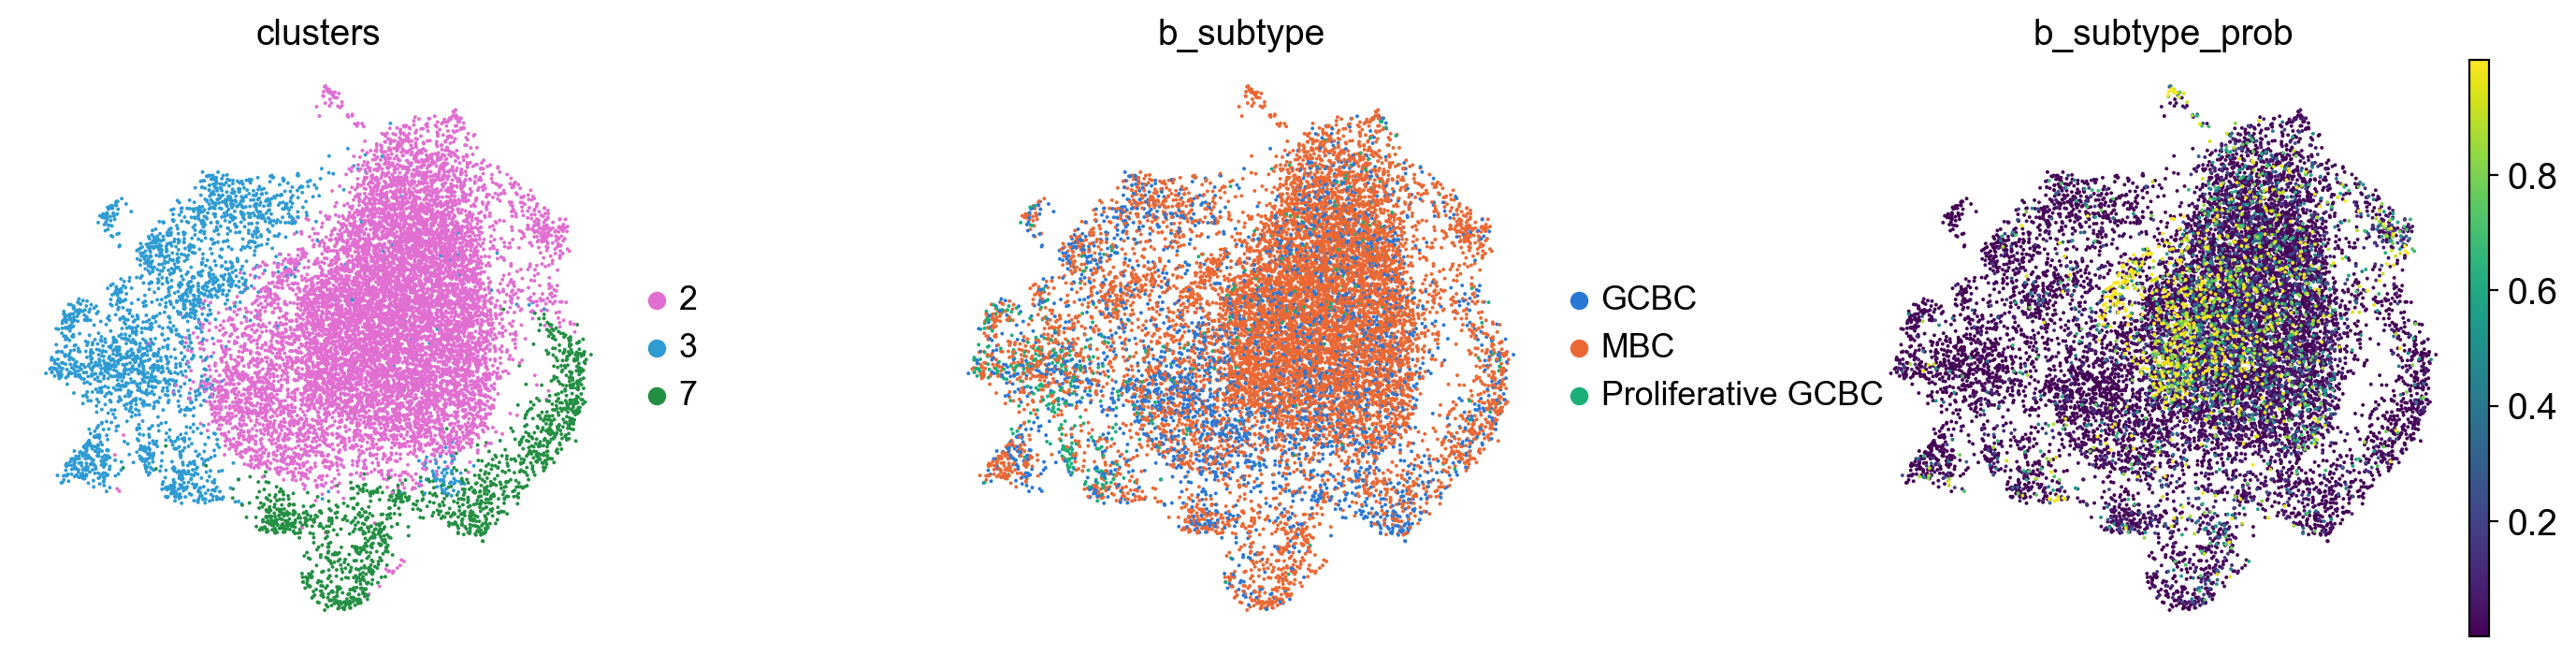

In [18]:
sc.pp.neighbors(b_cells, use_rep="X_pca_harmony")
sc.tl.umap(b_cells)

# Colours are assigned from the full b_order so a subtype keeps its colour even if another is empty.
b_colours = make_colour_dict(b_order)
b_cells.uns["b_subtype_colors"] = [b_colours[c] for c in b_cells.obs["b_subtype"].cat.categories]
b_cells.uns["clusters_colors"] = [cluster_colourmap[c] for c in b_cells.obs["clusters"].cat.categories]

sc.pl.umap(b_cells, color=["clusters", "b_subtype", "b_subtype_prob"], wspace=0.4,
           frameon=False, size=8, cmap="viridis", save="_b_subtypes.png")

**Marker gene check.** CellTypist is a prediction; always check it against known biology. If the
labels are right, GCBC should be high for BCL6/AICDA/RGS13, proliferative GCBC should add
MKI67/TOP2A, and MBC should be high for CD27/TNFRSF13B and low for the GC genes.

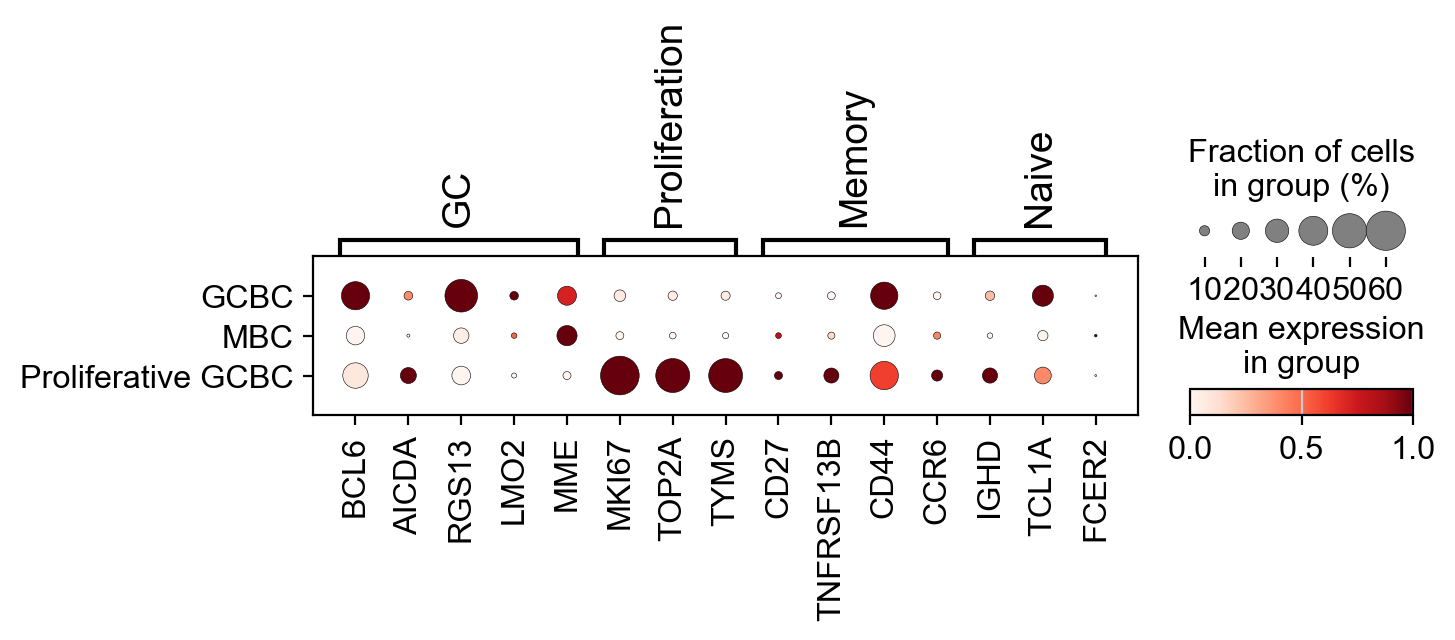

In [19]:
b_markers = {
    "GC":            ["BCL6", "AICDA", "RGS13", "LMO2", "MME"],
    "Proliferation": ["MKI67", "TOP2A", "TYMS"],
    "Memory":        ["CD27", "TNFRSF13B", "CD44", "CCR6"],
    "Naive":         ["IGHD", "TCL1A", "FCER2"],
}
b_markers = {k: [g for g in v if g in b_cells.var_names] for k, v in b_markers.items()}

sc.pl.dotplot(b_cells, b_markers, groupby="b_subtype", standard_scale="var",
              save="_b_subtype_markers.png")

**Subtype make-up per cluster and per condition.**

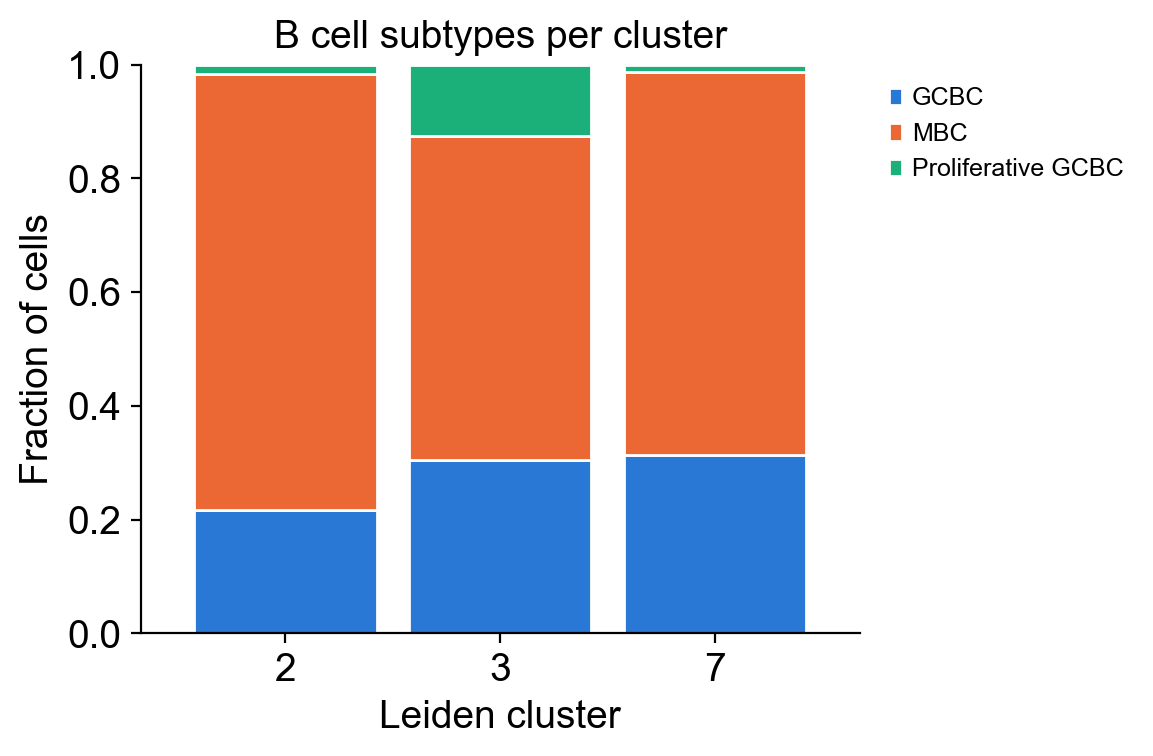

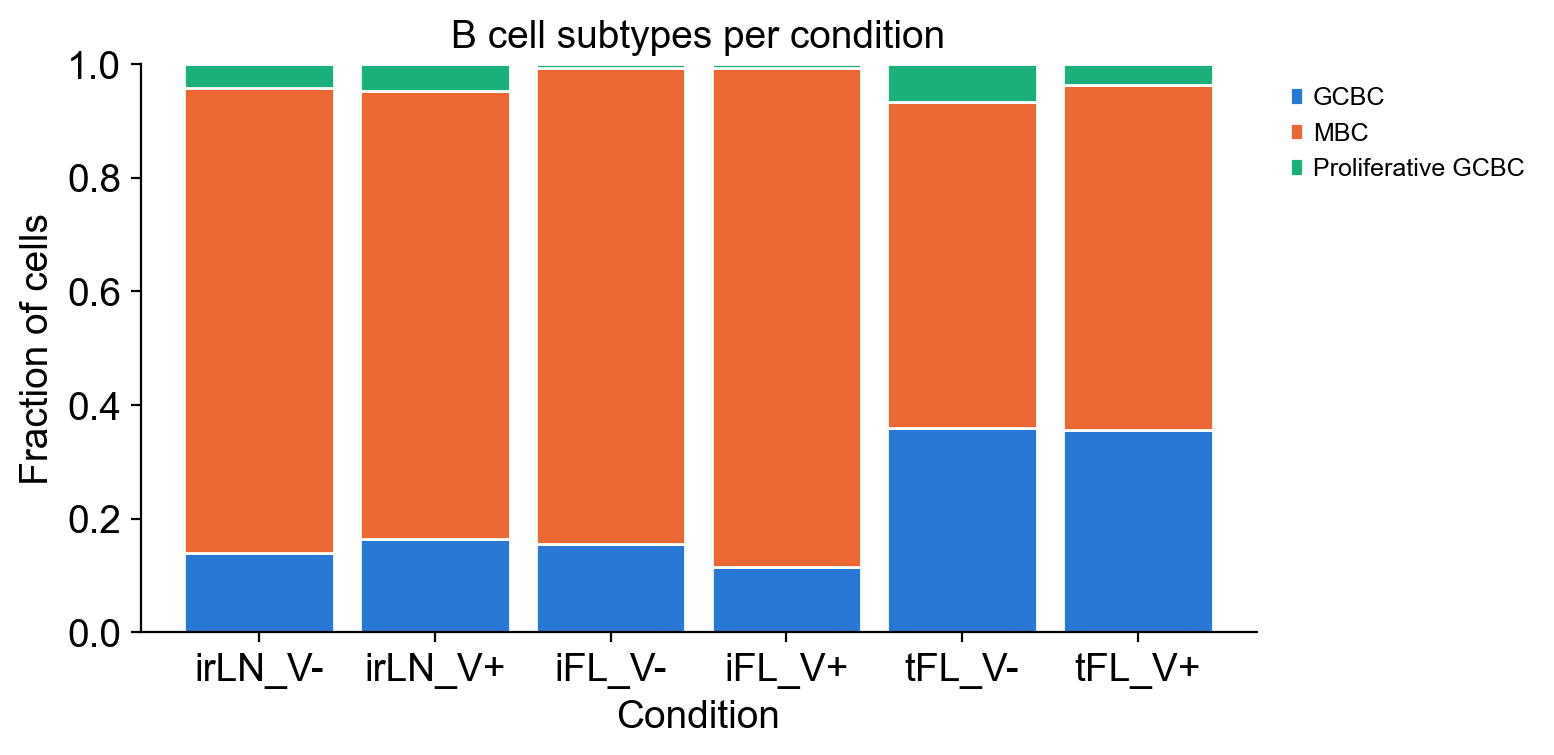

b_subtype,GCBC,MBC,Proliferative GCBC,All
condition,,,,
irLN_V-,176,1035,54,1265
irLN_V+,28,135,8,171
iFL_V-,715,3877,36,4628
iFL_V+,153,1167,10,1330
tFL_V-,1846,2937,340,5123
tFL_V+,363,621,37,1021
All,3281,9772,485,13538


In [20]:
b_by_cluster = pd.crosstab(b_cells.obs["clusters"], b_cells.obs["b_subtype"], normalize="index")
b_by_cluster = b_by_cluster.loc[b_by_cluster.sum(axis=1) > 0]
plot_stacked_fractions(b_by_cluster, b_colours, "B cell subtypes per cluster",
                       "Leiden cluster", "b_subtypes_per_cluster.png", figsize=(6, 4))

b_by_condition = pd.crosstab(b_cells.obs["condition"], b_cells.obs["b_subtype"], normalize="index")
plot_stacked_fractions(b_by_condition, b_colours, "B cell subtypes per condition",
                       "Condition", "b_subtypes_per_condition.png")

# Raw numbers matter: a fraction from 20 cells is far less reliable than one from 2,000.
pd.crosstab(b_cells.obs["condition"], b_cells.obs["b_subtype"], margins=True)

## Step 3: T cell subtypes

Exactly the same recipe as Step 2.

### 3a. Select T cells

In [21]:
t_clusters = cluster_summary.index[cluster_summary["designation"] == "T cells"].tolist()
print("T cell clusters:", t_clusters)

t_allowed_high_labels = ["T cells", "Cycling cells"]

in_t_cluster = adata.obs["clusters"].isin(t_clusters)
is_t_cell = adata.obs["ct_high_label"].isin(t_allowed_high_labels)
t_mask = in_t_cluster & is_t_cell

print(f"Cells in T clusters:         {in_t_cluster.sum()}")
print(f"  kept for subtyping:        {t_mask.sum()}")
print(f"  excluded (by High label):")
print(adata.obs.loc[in_t_cluster & ~is_t_cell, "ct_high_label"].astype(str).value_counts().to_string())

t_cells = ct_input[t_mask.values].copy()

T cell clusters: ['4']
Cells in T clusters:         3754
  kept for subtyping:        3674
  excluded (by High label):
ct_high_label
ILC                           49
B cells                       14
Plasma cells                   7
Macrophages                    4
Endothelial cells              2
Double-positive thymocytes     1
Erythroid                      1
Myelocytes                     1
Fibroblasts                    1


### 3b–c. Run the Low model and assign the six requested subtypes

Mapping notes (requested name → CellTypist Low label):
* **Tem/effector helper** combines `Tem/Effector helper T cells` and its `PD1+` variant; the cell
  takes whichever of the two scores higher.
* **Cycling Tem/Trm cytotoxic**: the Low model has no label with exactly this name. Its closest
  label is `Cycling T cells`, which is what we use. The marker dotplot below lets you confirm
  these cells are cytotoxic (CD8A, GZMK…) as well as cycling (MKI67).
* **Treg** = `Regulatory T cells`.

In [22]:
t_pred = celltypist.annotate(t_cells, model=low_model, majority_voting=False)
t_prob = t_pred.probability_matrix
t_cells.obs["low_best_label"] = t_pred.predicted_labels["predicted_labels"].values

t_subtype_definitions = {
    "Tcm/naive helper":          ["Tcm/Naive helper T cells"],
    "Tem/effector helper":       ["Tem/Effector helper T cells", "Tem/Effector helper T cells PD1+"],
    "Tem/Trm cytotoxic":         ["Tem/Trm cytotoxic T cells"],
    "Cycling Tem/Trm cytotoxic": ["Cycling T cells"],
    "Tem/Temra cytotoxic":       ["Tem/Temra cytotoxic T cells"],
    "Treg":                      ["Regulatory T cells"],
}
t_order = list(t_subtype_definitions) + ["Low confidence"]

subtype, score, t_scores = assign_subtypes(t_prob, t_subtype_definitions, min_prob=0.0)
t_cells.obs["t_subtype"] = pd.Categorical(subtype.values, categories=t_order).remove_unused_categories()
t_cells.obs["t_subtype_prob"] = score.values

print("Probability quantiles per requested subtype:")
print(t_scores.quantile([0.5, 0.9, 0.99]).round(3).T, "\n")

t_cells.obs["t_subtype"].value_counts()

🔬 Input data has 3674 cells and 55689 genes
🔗 Matching reference genes in the model
🧬 5889 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


Probability quantiles per requested subtype:
                            0.50   0.90   0.99
Tcm/naive helper           0.325  0.998  1.000
Tem/effector helper        0.000  0.001  0.026
Tem/Trm cytotoxic          0.000  0.005  0.504
Cycling Tem/Trm cytotoxic  0.000  0.000  0.003
Tem/Temra cytotoxic        0.000  0.000  0.001
Treg                       0.000  0.783  1.000 



t_subtype
Tcm/naive helper             2558
Treg                          779
Tem/Trm cytotoxic             273
Tem/effector helper            57
Tem/Temra cytotoxic             4
Cycling Tem/Trm cytotoxic       3
Name: count, dtype: int64

Where did the unconstrained labels go? (e.g. *Follicular helper T cells* were not requested, so
they get pushed into whichever requested subtype they most resemble.) Expect some requested
subtypes to be very small or absent if those cells simply aren't in the culture.

In [23]:
pd.crosstab(t_cells.obs["low_best_label"], t_cells.obs["t_subtype"]).sort_values("Tcm/naive helper", ascending=False)

t_subtype,Tcm/naive helper,Tem/effector helper,Tem/Trm cytotoxic,Cycling Tem/Trm cytotoxic,Tem/Temra cytotoxic,Treg
low_best_label,,,,,,
Tcm/Naive helper T cells,2387,0,0,0,0,0
NK cells,33,7,22,1,1,12
Follicular helper T cells,31,8,9,0,0,15
CD16- NK cells,27,3,10,1,0,7
Tcm/Naive cytotoxic T cells,24,2,10,1,1,0
Naive B cells,15,1,13,0,0,12
Plasma cells,7,1,3,0,0,1
Alveolar macrophages,6,1,1,0,0,3
Classical monocytes,5,0,1,0,0,1


### 3d. Visualise the T cell subtypes

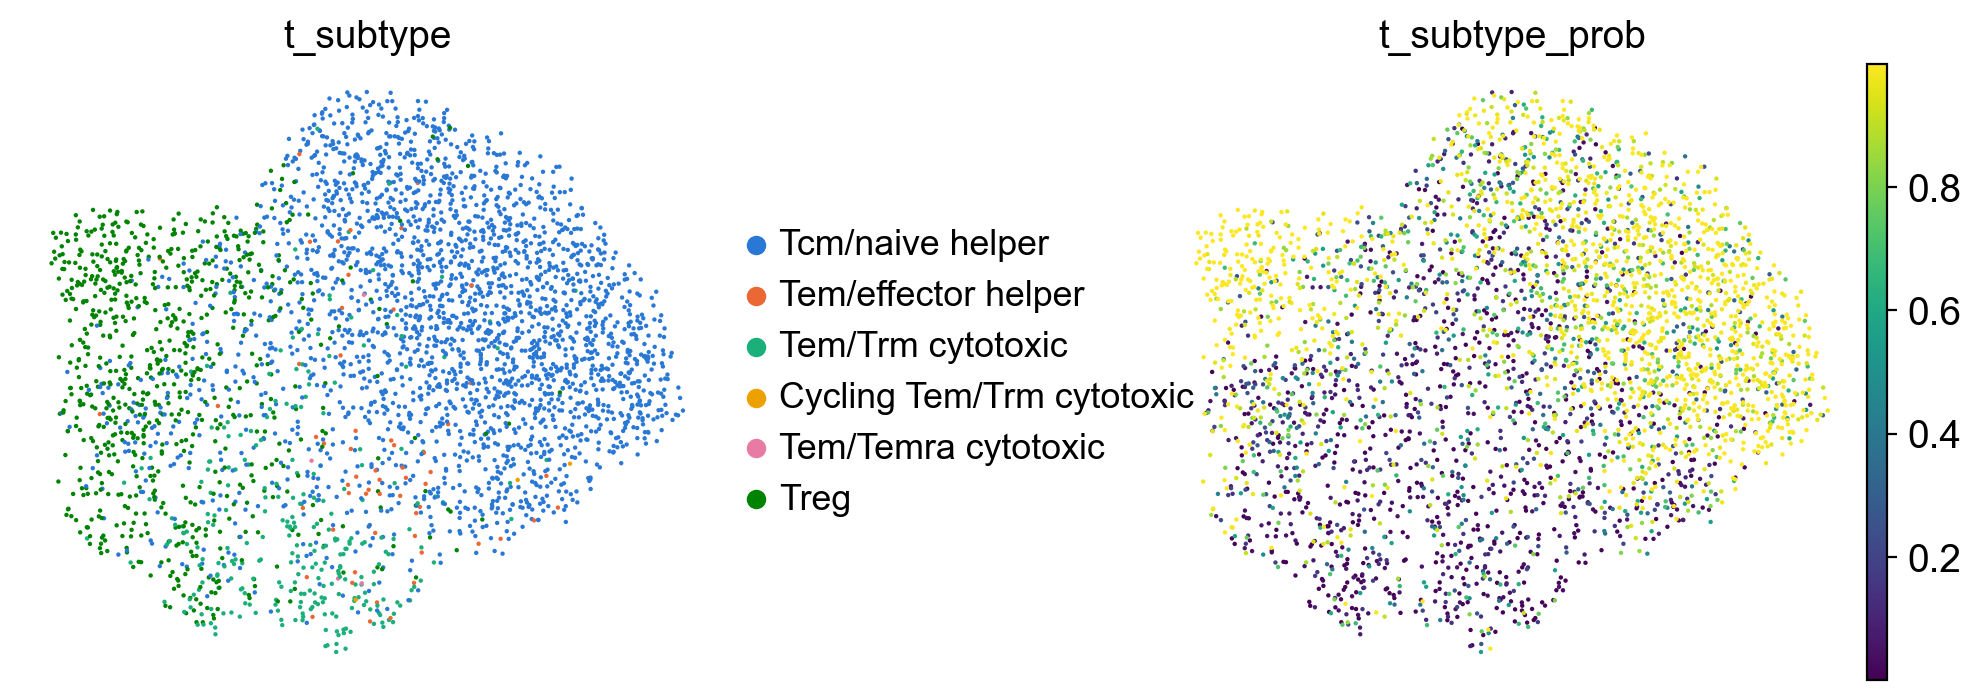

In [24]:
sc.pp.neighbors(t_cells, use_rep="X_pca_harmony")
sc.tl.umap(t_cells)

t_colours = make_colour_dict(t_order)
t_cells.uns["t_subtype_colors"] = [t_colours[c] for c in t_cells.obs["t_subtype"].cat.categories]
t_cells.uns["clusters_colors"] = [cluster_colourmap[c] for c in t_cells.obs["clusters"].cat.categories]

sc.pl.umap(t_cells, color=["t_subtype", "t_subtype_prob"], wspace=0.5,
           frameon=False, size=10, cmap="viridis", save="_t_subtypes.png")

**Marker gene check.** Expected pattern: Tcm/naïve: CCR7/SELL/TCF7 · helper: CD4/CD40LG ·
cytotoxic: CD8A/GZMK/NKG7 · Trm: ITGAE/CXCR6 · Temra: GZMH/CX3CR1 · cycling: MKI67/TOP2A ·
Treg: FOXP3/IL2RA/CTLA4.

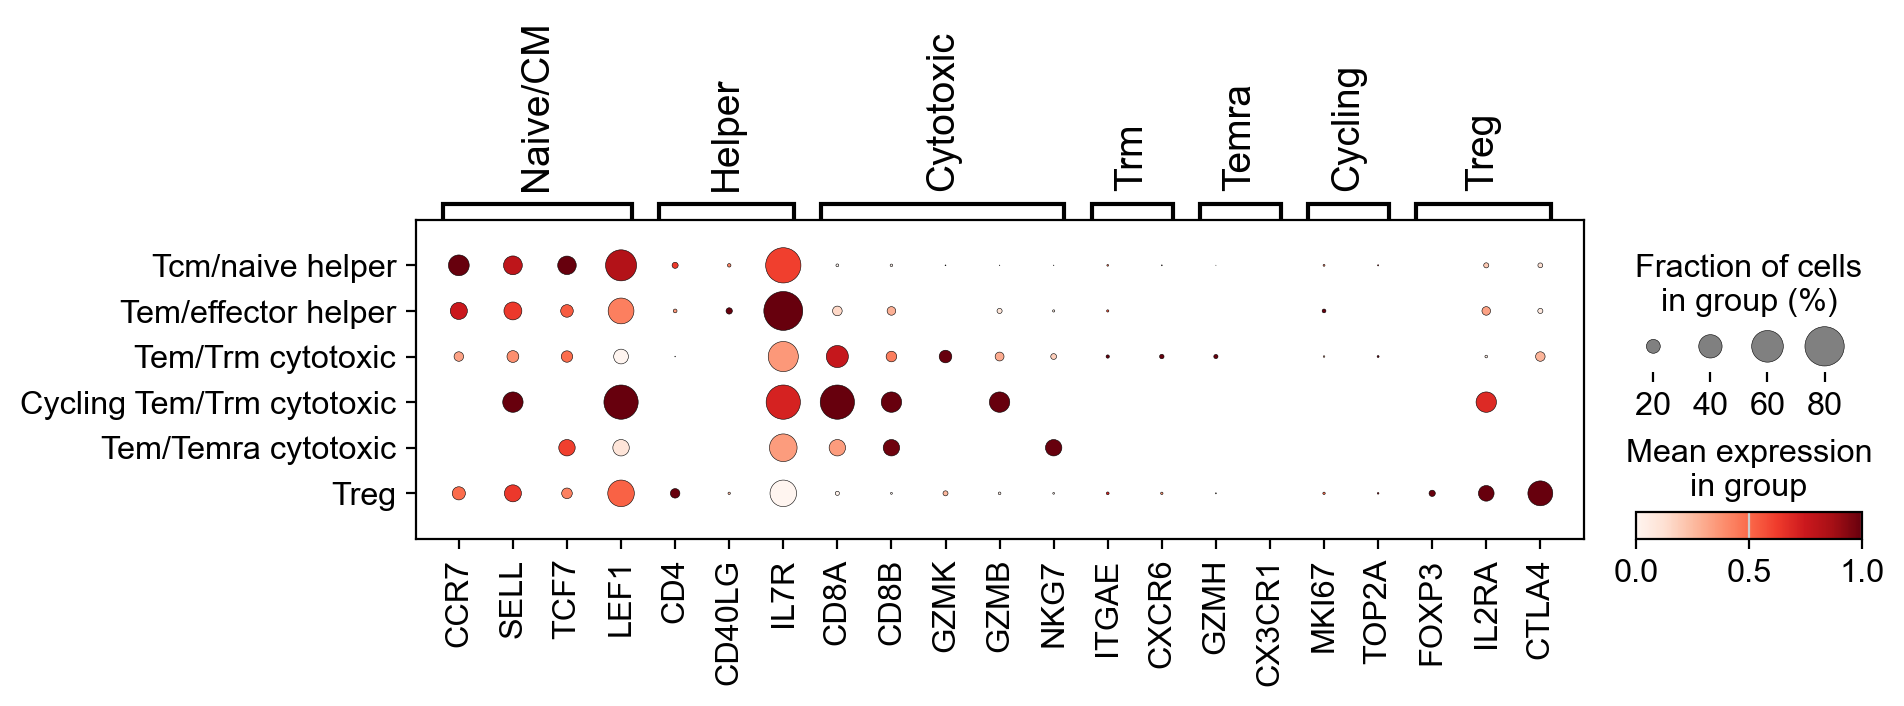

In [25]:
t_markers = {
    "Naive/CM":  ["CCR7", "SELL", "TCF7", "LEF1"],
    "Helper":    ["CD4", "CD40LG", "IL7R"],
    "Cytotoxic": ["CD8A", "CD8B", "GZMK", "GZMB", "NKG7"],
    "Trm":       ["ITGAE", "CXCR6"],
    "Temra":     ["GZMH", "CX3CR1"],
    "Cycling":   ["MKI67", "TOP2A"],
    "Treg":      ["FOXP3", "IL2RA", "CTLA4"],
}
t_markers = {k: [g for g in v if g in t_cells.var_names] for k, v in t_markers.items()}

sc.pl.dotplot(t_cells, t_markers, groupby="t_subtype", standard_scale="var",
              save="_t_subtype_markers.png")

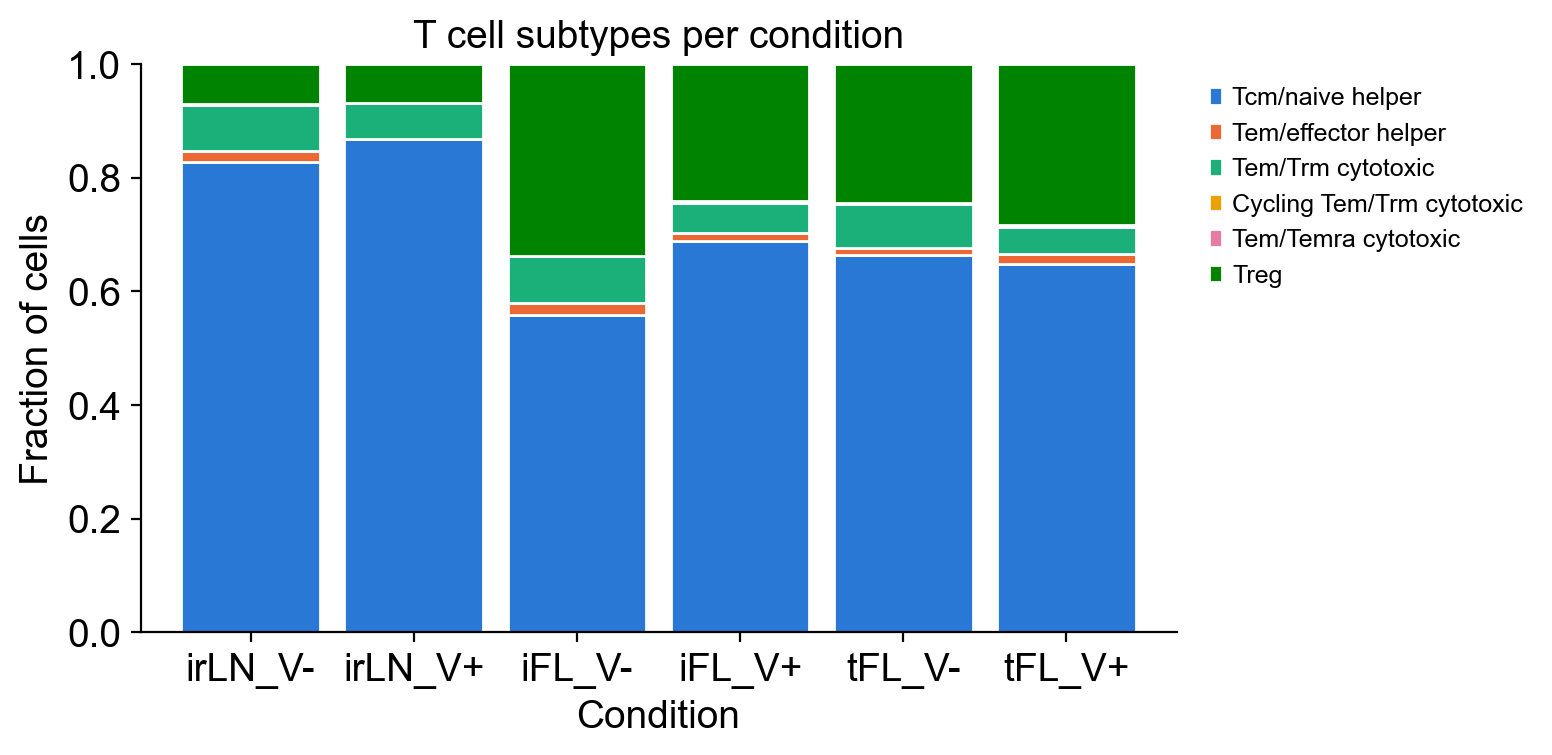

t_subtype,Tcm/naive helper,Tem/effector helper,Tem/Trm cytotoxic,Cycling Tem/Trm cytotoxic,Tem/Temra cytotoxic,Treg,All
condition,,,,,,,
irLN_V-,840,18,82,1,2,71,1014
irLN_V+,125,0,9,0,0,10,144
iFL_V-,418,15,62,0,0,253,748
iFL_V+,195,4,15,0,1,68,283
tFL_V-,761,14,89,2,0,281,1147
tFL_V+,219,6,16,0,1,96,338
All,2558,57,273,3,4,779,3674


In [26]:
t_by_condition = pd.crosstab(t_cells.obs["condition"], t_cells.obs["t_subtype"], normalize="index")
plot_stacked_fractions(t_by_condition, t_colours, "T cell subtypes per condition",
                       "Condition", "t_subtypes_per_condition.png")

pd.crosstab(t_cells.obs["condition"], t_cells.obs["t_subtype"], margins=True)

## Step 4: Save the annotations

We save a **per-cell table** (one row per barcode) rather than a new `.h5ad`. It is small, opens
in Excel, and can be merged back onto the cleaned dataset in any notebook with:

```python
annotations = pd.read_csv(".../celltypist_cell_annotations.csv", index_col=0)
adata.obs = adata.obs.join(annotations)
```

In [27]:
# Copy the subtype calls back onto the full object; cells that weren't subtyped get "Not subtyped".
adata.obs["ct_subtype"] = "Not subtyped"
adata.obs.loc[b_cells.obs_names, "ct_subtype"] = b_cells.obs["b_subtype"].astype(str)
adata.obs.loc[t_cells.obs_names, "ct_subtype"] = t_cells.obs["t_subtype"].astype(str)

adata.obs["ct_subtype_prob"] = np.nan
adata.obs.loc[b_cells.obs_names, "ct_subtype_prob"] = b_cells.obs["b_subtype_prob"]
adata.obs.loc[t_cells.obs_names, "ct_subtype_prob"] = t_cells.obs["t_subtype_prob"]

annotation_columns = ["clusters", "condition", "sample", "ct_high_label", "ct_high_prob",
                      "ct_lineage", "cluster_designation", "ct_subtype", "ct_subtype_prob"]
adata.obs[annotation_columns].to_csv(outdir / "celltypist_cell_annotations.csv")

# The full per-cell probability matrices too, in case you want to revisit thresholds later.
b_prob.to_csv(outdir / "b_cells_low_model_probabilities.csv")
t_prob.to_csv(outdir / "t_cells_low_model_probabilities.csv")

print("Saved to", outdir)
adata.obs["ct_subtype"].value_counts()

Saved to C:\Users\taylorhearn\Desktop\scRNA\celltypist


ct_subtype
Not subtyped                 41432
MBC                           9772
GCBC                          3281
Tcm/naive helper              2558
Treg                           779
Proliferative GCBC             485
Tem/Trm cytotoxic              273
Tem/effector helper             57
Tem/Temra cytotoxic              4
Cycling Tem/Trm cytotoxic        3
Name: count, dtype: int64

## Appendix: the collaborator's R function, in Python

This is a line-by-line translation of `r_celltypist_immune()` from `victor_celltypist_r.R`, run
on the **Low** model probabilities for **all** cells. Use it if you need numbers directly
comparable with your collaborator's.

What it does, per cell:
1. `celltypist_max` / `celltypist_max_prob`: the best label and its probability.
2. `celltypist_prob90`: **every** label with probability > 0.9, joined with `|`, or "Unassigned".
3. `mixing`: if more than one label passed, are they all B labels (`Mixed_B`), all T labels
   (`Mixed_T`), or a mix (`Mixed_other`)?
4. `lineage`: B_lineage / T_lineage / Other.
5. `final`: the single label, or the mixing category if several passed.

**Why it isn't the main method above:** a 90% cut-off on the 98-label model is very strict. The
Low model splits "B-cell-ness" across many similar labels (naive, memory, GC…), so often *no*
single label passes 0.9 and the cell becomes "Unassigned", even when it is clearly a B cell. The
table at the end shows how many cells per cluster this affects.

In [28]:
# Lineage lists copied verbatim from the R script.
blin = ["B cells", "Follicular B cells", "Proliferative germinal center B cells",
        "Germinal center B cells", "Memory B cells", "Age-associated B cells",
        "Naive B cells", "Transitional B cells", "Large pre-B cells",
        "Small pre-B cells", "Pre-pro-B cells", "Pro-B cells",
        "Cycling B cells", "Plasma cells", "Plasmablasts"]
tlin = ["Cycling gamma-delta T cells", "Cycling T cells", "Double-negative thymocytes",
        "Double-positive thymocytes", "ETP", "CD8a/a", "CD8a/b(entry)", "Follicular helper T cells",
        "CRTAM+ gamma-delta T cells", "gamma-delta T cells", "MAIT cells", "Memory CD4+ cytotoxic T cells",
        "NKT cells", "Regulatory T cells", "T(agonist)", "Tcm/Naive cytotoxic T cells",
        "Tcm/Naive helper T cells", "Tem/Trm cytotoxic T cells", "Tem/Temra cytotoxic T cells",
        "Trm cytotoxic T cells", "Tem/Effector helper T cells", "Tem/Effector helper T cells PD1+",
        "Treg(diff)", "Type 1 helper T cells", "Type 17 helper T cells"]


def celltypist_immune_threshold(prob_matrix, prob_threshold=90):
    # prob_matrix: cells x cell types (celltypist's .probability_matrix). Threshold in %, as in R.
    p = prob_threshold
    labels = prob_matrix.columns.to_numpy()
    df = pd.DataFrame(index=prob_matrix.index)

    # 1. Best label and its probability (R: which.max per row)
    df["celltypist_max"] = prob_matrix.idxmax(axis=1)
    df["celltypist_max_prob"] = prob_matrix.max(axis=1)

    # 2. All labels above the threshold, "|"-joined (R: paste(..., collapse="|"))
    passed = prob_matrix.to_numpy() > p / 100           # boolean cells x labels
    df[f"celltypist_prob{p}"] = ["|".join(labels[row]) or "Unassigned" for row in passed]

    # 3. Mixing: count how many passing labels are B / T labels
    n_passed = passed.sum(axis=1)
    n_b = passed[:, np.isin(labels, blin)].sum(axis=1)
    n_t = passed[:, np.isin(labels, tlin)].sum(axis=1)
    mixing = np.select(
        [n_passed <= 1, n_b == n_passed, n_t == n_passed],
        ["No_mixed",    "Mixed_B",       "Mixed_T"],
        default="Mixed_other",
    )

    # 4. Lineage: a single B label or Mixed_B -> B_lineage (likewise for T), else Other
    single = df[f"celltypist_prob{p}"]
    lineage = np.select(
        [single.isin(blin) | (mixing == "Mixed_B"), single.isin(tlin) | (mixing == "Mixed_T")],
        ["B_lineage", "T_lineage"],
        default="Other",
    )
    df[f"celltypist_{p}_mixing"] = mixing
    df[f"celltypist_{p}_lineage"] = lineage

    # 5. Final: the single label, or the mixing category when several labels passed
    df[f"celltypist_{p}_final"] = np.where(mixing == "No_mixed", single, mixing)

    # Unassigned cells are Unassigned in every column
    unassigned = single == "Unassigned"
    for col in [f"celltypist_{p}_mixing", f"celltypist_{p}_lineage", f"celltypist_{p}_final"]:
        df.loc[unassigned, col] = "Unassigned"
    return df


low_pred_all = celltypist.annotate(ct_input, model=low_model, majority_voting=False)
collab = celltypist_immune_threshold(low_pred_all.probability_matrix, prob_threshold=90)
collab.to_csv(outdir / "collaborator_method_low_model_prob90.csv")

# Lineage per cluster with the collaborator's method (percent of cells):
(pd.crosstab(adata.obs["clusters"], collab.loc[adata.obs_names, "celltypist_90_lineage"],
             normalize="index") * 100).round(1)

🔬 Input data has 58644 cells and 55689 genes
🔗 Matching reference genes in the model
🧬 5889 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


celltypist_90_lineage,B_lineage,Other,T_lineage,Unassigned
clusters,,,,
0,0.0,99.5,0.0,0.5
1,0.0,70.7,0.0,29.2
2,14.8,0.1,0.2,84.9
3,15.7,1.0,0.6,82.7
4,0.1,0.1,40.3,59.5
5,0.1,12.5,1.4,86.1
6,0.0,99.1,0.0,0.8
7,2.0,0.4,0.2,97.5
8,0.0,98.3,0.0,1.7


## Things worth knowing / possible next steps

* **Thresholds are choices.** `designation_threshold` (Step 1) and `min_prob` (Steps 2–3) are
  parameters. Re-run with different values and see what's robust.
* **Model context.** `Immune_All_*` was trained on immune cells from healthy and developing tissues,
  not on follicular lymphoma. Malignant FL B cells resemble GC B cells (BCL6+, CD10/MME+), so expect
  many of them to be called GCBC. The marker dotplot is your best sanity check.
* **Non-immune clusters.** CellTypist's immune models do contain *Endothelial cells* and
  *Fibroblasts* labels, which is why clusters 0/1/6/8 are called confidently, but they are not
  designed to subtype stromal cells.
* **Majority voting.** `celltypist.annotate(..., majority_voting=True, over_clustering="clusters")`
  would relabel every cell in a cluster with the cluster's most common label. That's a fast way
  to name clusters but hides the within-cluster mixing that Step 1 shows.